# Image Classsification with Neural network

In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# initialize the seeds
keras.utils.set_random_seed(20)

In [3]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

In [4]:
print(x_train.shape, y_train.shape)

print(x_test.shape, y_test.shape)

(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)


In [5]:
print(np.unique(y_train))

[0 1 2 3 4 5 6 7 8 9]


**What do these numbers mean?**

According to the [Fashion MNIST Github site](https://github.com/zalandoresearch/fashion-mnist#labels), this is what each number 0-9 corresponds to:

| Label  | Description  |
|---|---|
|  0 | T-shirt/top  |
|  1 |  Trouser |
|  2 |   Pullover |
|  3 |  Dress |
|  4 |  Coat |
|  5 |  Sandal |
|  6 |   Shirt |
|  7 |  Sneaker |
|  8 |   Bag |
|  9 |  Ankle boot |

In [6]:
labels = ["T-shirt/top",
          "Trouser",
          "Pullover",
          "Dress",
          "Coat",
          "Sandal",
          "Shirt",
          "Sneaker",
          "Bag",
          "Ankle boot"]

#### Visualise the first few images

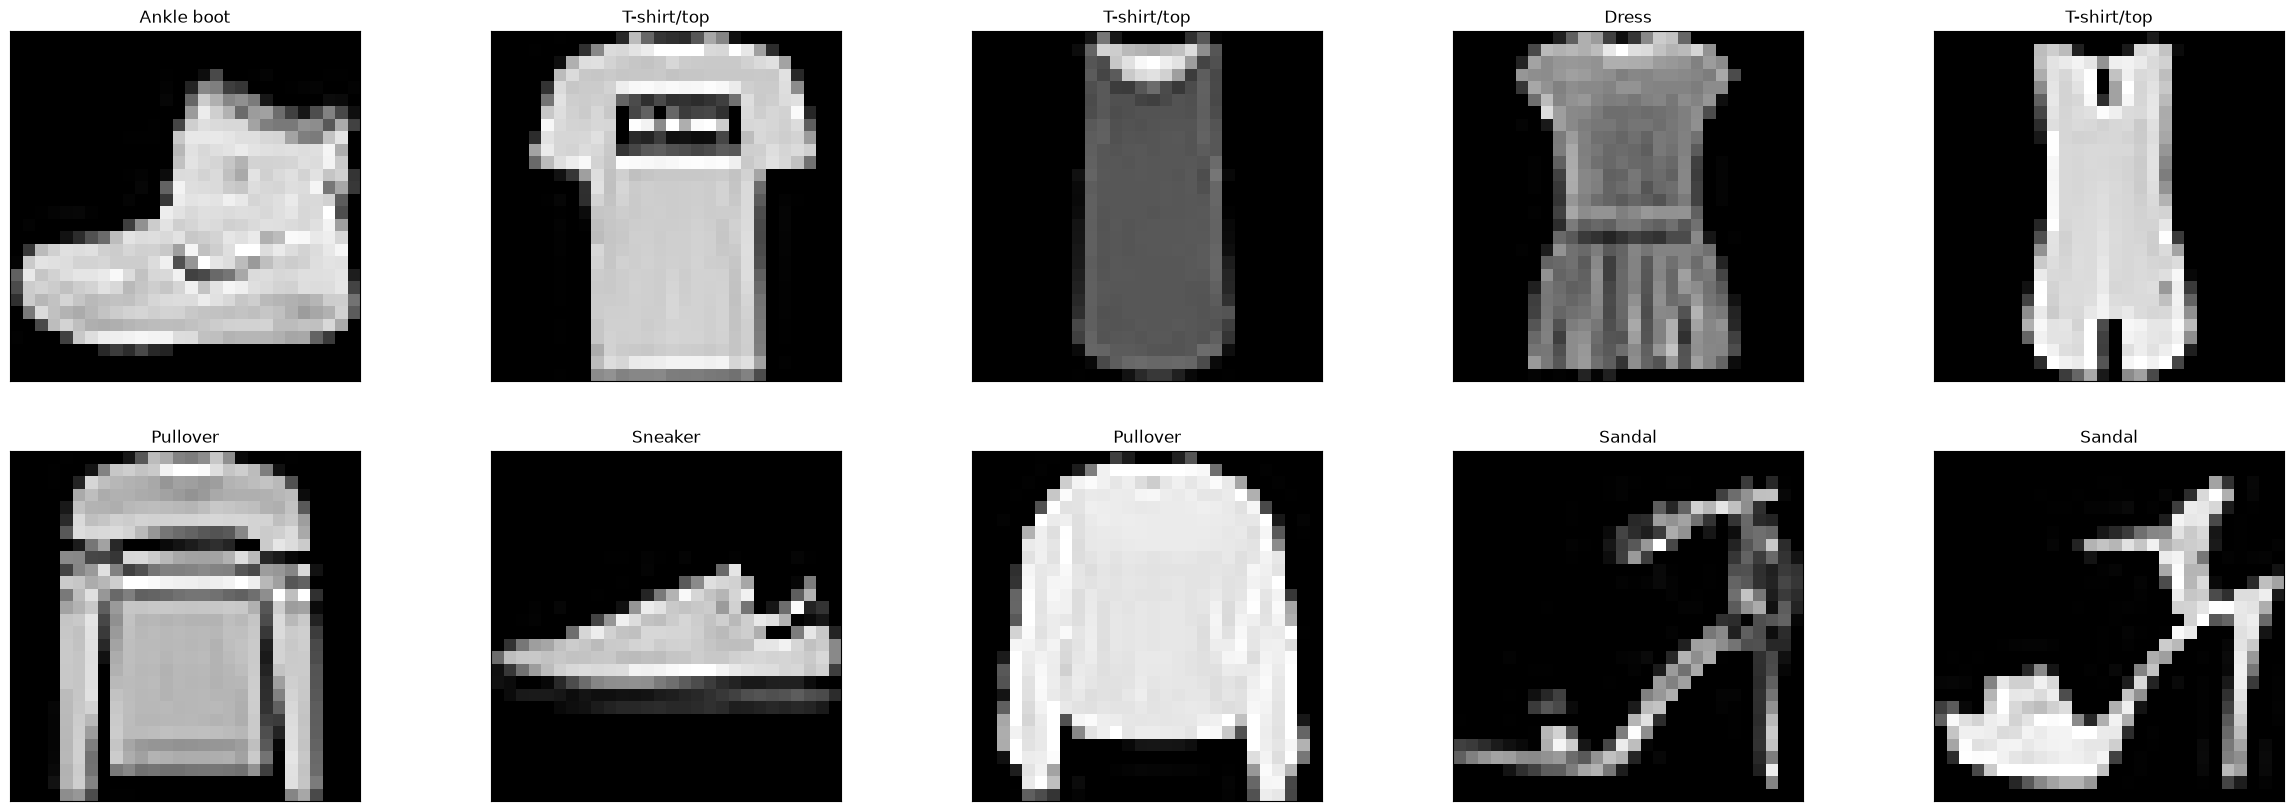

In [7]:
fig, ax = plt.subplots(2, 5, figsize=(30, 10))
for i in range(10):
  axc = ax[i//5, i%5]
  axc.imshow(x_train[i], cmap="gray")
  axc.set_title(f"{labels[y_train[i]]}")
  axc.set_xticks([])
  axc.set_yticks([])

### Data preprocessing

The data ranges from 0-255 because the images are black and white  
to ensure the numbers are not too far from each other 
- Prevents Feature Dominance
- To ensure faster convergence

Normalize to the 0-1 range by dividing everything by 255.

In [8]:
x_train = x_train/ 255
x_test = x_test/ 255

### The model

In [9]:
def build_model():
    # The images are 28 by 28 pixels each
    inputs = keras.Input(shape=(28, 28))
    h = keras.layers.Flatten()(inputs)
    h = keras.layers.Dense(256, activation="relu")(h)
    outputs = keras.layers.Dense(10, activation="softmax")(h)

    model = keras.Model(inputs, outputs)

    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer="adam",
        metrics=["accuracy"]
    )
    return model

In [10]:
model = build_model()

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,530 (795.04 KB)

 Trainable params: 203,530 (795.04 KB)

 Non-trainable params: 0 (0.00 B)

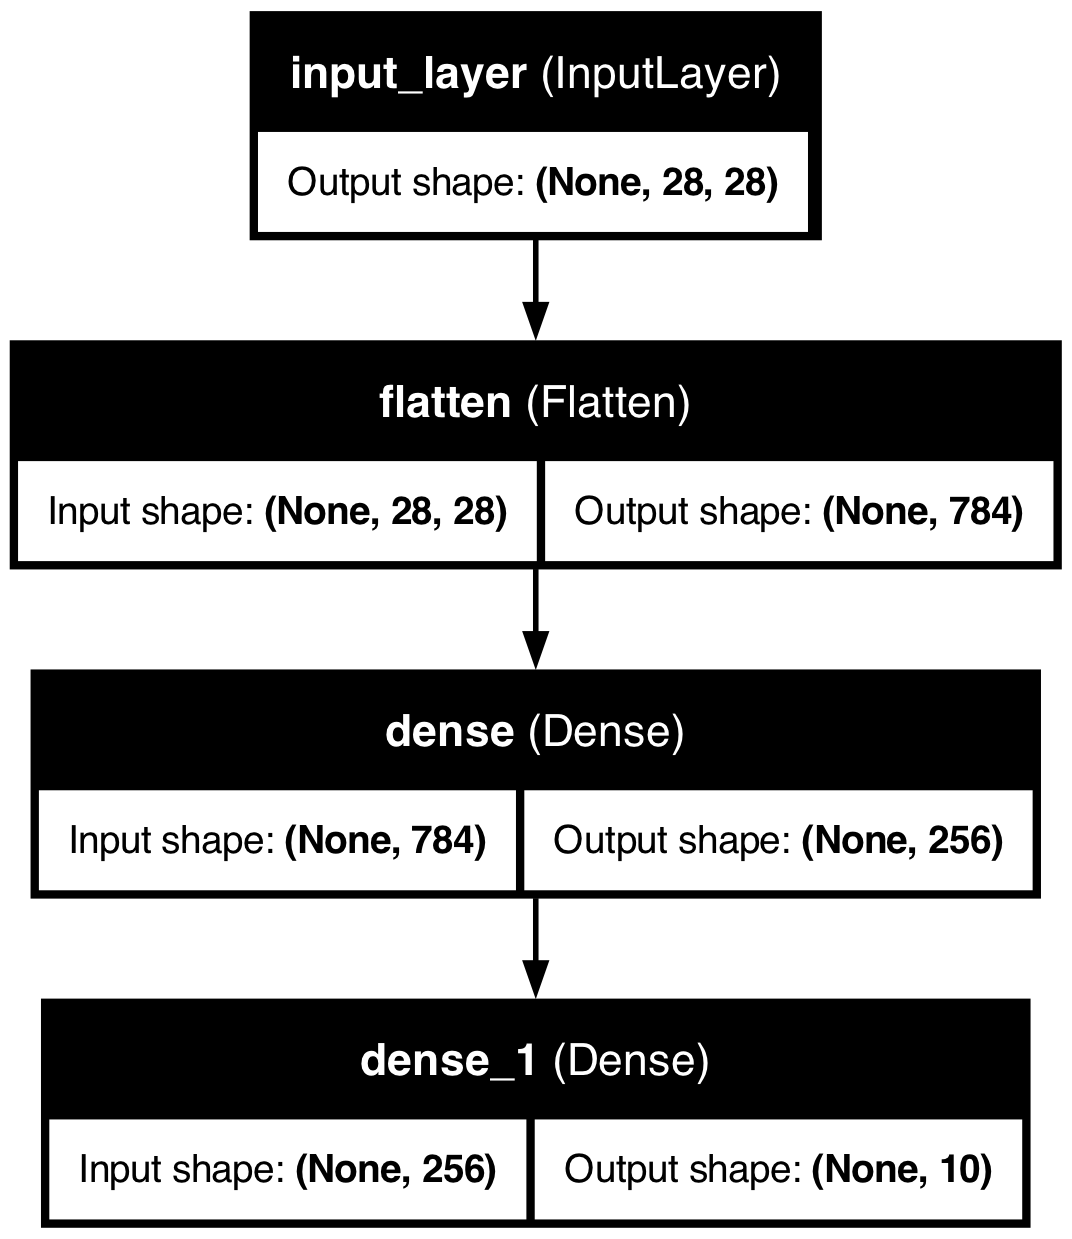

In [11]:
keras.utils.plot_model(model, show_shapes=True, show_layer_names=True)

#### Train the model

In [12]:
batch_size = 64
epochs = 15

history = model.fit(x_train,
                    y_train,
                    batch_size=batch_size,
                    epochs=epochs,
                    validation_split=0.2)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8199 - loss: 0.5141 - val_accuracy: 0.8132 - val_loss: 0.5109
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8614 - loss: 0.3876 - val_accuracy: 0.8540 - val_loss: 0.3991
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8745 - loss: 0.3437 - val_accuracy: 0.8643 - val_loss: 0.3690
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8846 - loss: 0.3159 - val_accuracy: 0.8702 - val_loss: 0.3527
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8919 - loss: 0.2938 - val_accuracy: 0.8728 - val_loss: 0.3458
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8980 - loss: 0.2766 - val_accuracy: 0.8745 - val_loss: 0.3433
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9035 - loss: 0.2622 - val_accuracy: 0.8780 - val_loss: 0.3362
Epoch 8/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9077 - loss: 0.2499 - val_accuracy: 0.

In [13]:
## Helper functions
def plot_loss_curves(history):
  plt.clf()
  history_dict = history.history
  loss_values = history_dict["loss"]
  val_loss_values = history_dict["val_loss"]
  epochs = range(1, len(loss_values) + 1)
  plt.plot(epochs, loss_values, "bo", label="Training loss")
  plt.plot(epochs, val_loss_values, "b", label="Validation loss")
  plt.title("Training and validation loss")
  plt.xlabel("Epochs")
  plt.ylabel("Loss")
  plt.legend()
  plt.show()


def plot_acc_curves(history):
  plt.clf()
  history_dict = history.history
  acc = history_dict["accuracy"]
  val_acc = history_dict["val_accuracy"]
  epochs = range(1, len(acc) + 1)
  plt.plot(epochs, acc, "bo", label="Training acc")
  plt.plot(epochs, val_acc, "b", label="Validation acc")
  plt.title("Training and validation accuracy")
  plt.xlabel("Epochs")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.show()

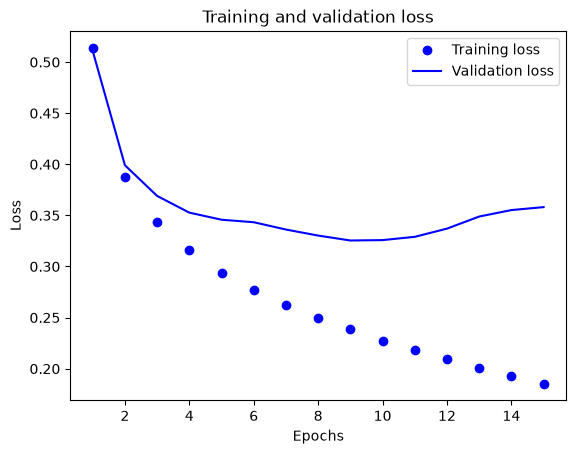

In [14]:

plot_loss_curves(history)


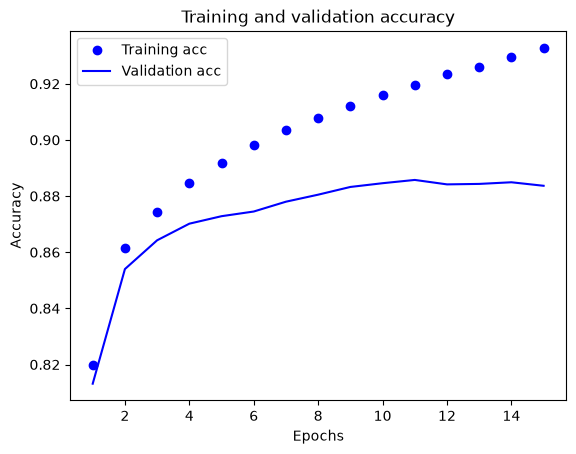

In [15]:
plot_acc_curves(history)

In [16]:
model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 423us/step - accuracy: 0.8730 - loss: 0.3895


[0.38950109481811523, 0.8730000257492065]

In [36]:
early_model = build_model()

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

early_history = early_model.fit(x_train,
                    y_train,
                    batch_size=batch_size,
                    epochs=epochs,
                    validation_split=0.2,
                    callbacks=[early_stopping])

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8190 - loss: 0.5172 - val_accuracy: 0.8188 - val_loss: 0.4969
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8606 - loss: 0.3888 - val_accuracy: 0.8508 - val_loss: 0.4103
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8739 - loss: 0.3460 - val_accuracy: 0.8611 - val_loss: 0.3823
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8832 - loss: 0.3174 - val_accuracy: 0.8694 - val_loss: 0.3614
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8914 - loss: 0.2972 - val_accuracy: 0.8695 - val_loss: 0.3587
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8970 - loss: 0.2805 - val_accuracy: 0.8691 - val_loss: 0.3677
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9023 - loss: 0.2650 - val_accuracy: 0.8751 - val_loss: 0.3562
Epoch 8/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9064 - loss: 0.2526 - val_accuracy: 0.

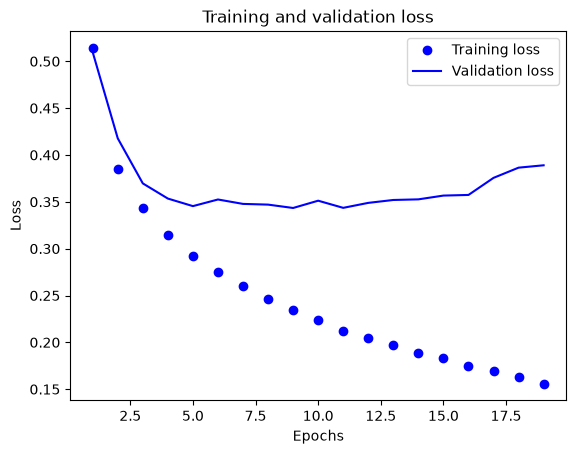

In [33]:
plot_loss_curves(early_history)

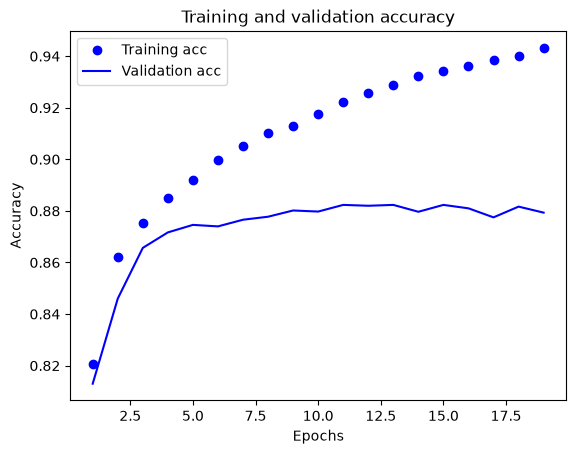

In [34]:
plot_acc_curves(early_history)

In [35]:
early_model.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 401us/step - accuracy: 0.8739 - loss: 0.3678


[0.36775657534599304, 0.8738999962806702]

### Add an additional hidden layer

In [25]:
## add an additional hidden layer

def model_double_hidden():
    input = keras.Input(shape=(28,28))

    h = keras.layers.Flatten()(input)
    
    h = keras.layers.Dense(256, activation="relu", name="Hidden_1")(h)
    h = keras.layers.Dense(256, activation="relu", name="Hidden_2")(h)
    
    output = keras.layers.Dense(10, activation="softmax", name="Output")(h)
    
    model = keras.Model(input, output)
    
    model.summary()
    
    model.compile(loss="sparse_categorical_crossentropy",
                  optimizer="adam",
                  metrics=["accuracy"])

    return model


In [26]:
model_double_h = model_double_hidden()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 28, 28)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_1 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_2 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output (Dense)                  │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 269,322 (1.03 MB)

 Trainable params: 269,322 (1.03 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
batch_size = 64
epochs = 20

history_double_hidden = model_double_h.fit(x_train,
                    y_train,
                    batch_size=batch_size,
                    epochs=epochs,
                    validation_split=0.2)

Epoch 1/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8220 - loss: 0.5000 - val_accuracy: 0.8304 - val_loss: 0.4597
Epoch 2/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8656 - loss: 0.3668 - val_accuracy: 0.8542 - val_loss: 0.3876
Epoch 3/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8794 - loss: 0.3271 - val_accuracy: 0.8618 - val_loss: 0.3713
Epoch 4/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8873 - loss: 0.3005 - val_accuracy: 0.8742 - val_loss: 0.3471
Epoch 5/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8959 - loss: 0.2785 - val_accuracy: 0.8728 - val_loss: 0.3528
Epoch 6/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9016 - loss: 0.2630 - val_accuracy: 0.8802 - val_loss: 0.3412
Epoch 7/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9068 - loss: 0.2490 - val_accuracy: 0.8748 - val_loss: 0.3591
Epoch 8/20
750/750 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9111 - loss: 0.2346 - val_accuracy: 0.

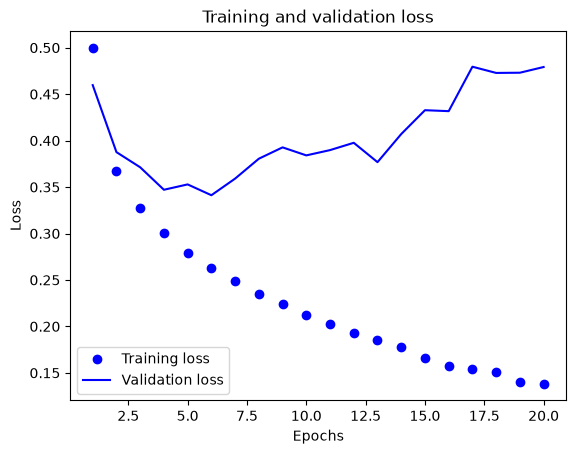

In [29]:
plot_loss_curves(history_double_hidden)

In [30]:
model_double_h.evaluate(x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 479us/step - accuracy: 0.8665 - loss: 0.5160


[0.516048789024353, 0.8665000200271606]

## Adding a additional hidden layer does not improve the model